In [12]:
from pathlib import Path

masks_path = Path("../data/labeled/masks")

available_masks = [mask.stem for mask in masks_path.glob("*.png")]

In [13]:
import cv2
import numpy as np

In [14]:
def check_circle(
    center, radius, circle_mask, has_colonies_mask, colony_mask, previous_circles_mask
):
    if center[0] - radius < 0 or center[1] - radius < 0:
        return False, previous_circles_mask
    elif (
        center[0] + radius >= circle_mask.shape[1]
        or center[1] + radius >= circle_mask.shape[0]
    ):
        return False, previous_circles_mask
    elif circle_mask[center[0], center[1]] == 0:
        return False, previous_circles_mask

    proposed_circle_filled = np.zeros_like(circle_mask, dtype=np.uint8)
    cv2.circle(proposed_circle_filled, center, radius, 1, -1)
    proposed_circle_area = np.sum(proposed_circle_filled)

    circle_mask_overlap = np.sum(np.logical_and(proposed_circle_filled, circle_mask))

    is_in_valid_area = circle_mask_overlap == proposed_circle_area

    has_colonies = np.any(np.logical_and(proposed_circle_filled, has_colonies_mask) > 0)

    proposed_circle_outlined = np.zeros_like(circle_mask, dtype=np.uint8)
    cv2.circle(proposed_circle_outlined, center, radius + 10, 1, 12)

    no_colony_overlap = not np.any(
        np.logical_and(proposed_circle_outlined, colony_mask) > 0
    )

    if previous_circles_mask is None:
        previous_circles_mask = np.zeros_like(circle_mask, dtype=np.uint8)

    previous_circle_overlap = np.sum(
        np.logical_and(proposed_circle_filled, previous_circles_mask)
    )

    acceptable_previous_circle_overlap = (
        previous_circle_overlap < 0.2 * proposed_circle_area
    )

    is_valid = (
        is_in_valid_area
        and has_colonies
        and no_colony_overlap
        and acceptable_previous_circle_overlap
    )

    if is_valid:
        cv2.circle(previous_circles_mask, center, radius, 1, -1)
        cv2.circle(has_colonies_mask, center, radius, 0, -1)

    return is_valid, previous_circles_mask

In [15]:
def generate_random_circle(
    circle_mask, has_colonies_mask, colony_mask, previous_circles_mask, tries=1000
):
    max_center = circle_mask.shape[0]
    min_radius = 10
    max_radius = 250

    for i in range(tries):
        center = np.random.randint(0, max_center, 2)
        radius = np.random.randint(min_radius, max_radius)

        is_valid, new_previous_circles_mask = check_circle(
            center,
            radius,
            circle_mask,
            has_colonies_mask,
            colony_mask,
            previous_circles_mask,
        )

        if is_valid:
            return i, (center, radius), new_previous_circles_mask

    return None, None, None

Found circle after tries: 12
Found circle after tries: 38
Found circle after tries: 4
Found circle after tries: 22
Found circle after tries: 14
Found circle after tries: 25
Found circle after tries: 31
Found circle after tries: 2
Found circle after tries: 109
Found circle after tries: 127
Found circle after tries: 1
Found circle after tries: 51
Found circle after tries: 176
Found circle after tries: 586
Found circle after tries: 485
Found circle after tries: 526
Found circle after tries: 869
Found circle after tries: 132
Found circle after tries: 339
Found circle after tries: 206
Found circle after tries: 50
Found circle after tries: None


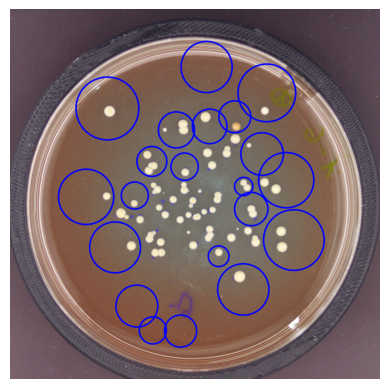

Found circles: [(array([1367,  993]), 138), (array([1982, 1643]), 127), (array([1173, 2640]), 101), (array([1401, 2646]), 122), (array([2110,  689]), 227), (array([1916, 2304]), 201), (array([1615,  476]), 200), (array([1042, 2440]), 162), (array([2269, 1406]), 217), (array([ 863, 1958]), 199), (array([2071, 1191]), 165), (array([800, 817]), 248), (array([2332, 1898]), 239), (array([ 625, 1543]), 217), (array([1025, 1532]), 101), (array([1640,  964]), 132), (array([1714, 2031]), 75), (array([1434, 1295]), 102), (array([1847,  885]), 121), (array([1920, 1458]), 65), (array([1165, 1252]), 113)]
Found circle after tries: 75
Found circle after tries: 58
Found circle after tries: 32
Found circle after tries: 5
Found circle after tries: 178
Found circle after tries: 65
Found circle after tries: 13
Found circle after tries: 58
Found circle after tries: 134
Found circle after tries: None


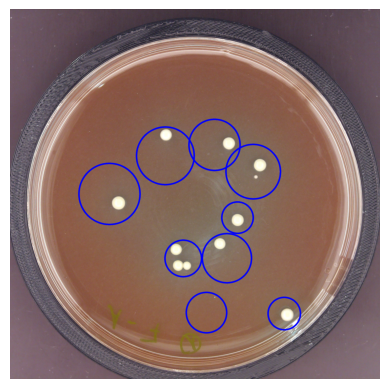

Found circles: [(array([1276, 1206]), 227), (array([1423, 2049]), 140), (array([1614, 2494]), 156), (array([1998, 1336]), 214), (array([ 817, 1519]), 241), (array([2253, 2502]), 123), (array([1869, 1714]), 119), (array([1782, 2047]), 192), (array([1680, 1116]), 200)]
Found circle after tries: 54
Found circle after tries: 10
Found circle after tries: 12
Found circle after tries: 176
Found circle after tries: 82
Found circle after tries: 91
Found circle after tries: 127
Found circle after tries: 172
Found circle after tries: 24
Found circle after tries: 478
Found circle after tries: 389
Found circle after tries: 342
Found circle after tries: 404


KeyboardInterrupt: 

In [16]:
import matplotlib.pyplot as plt
import json

dict = {}

for mask_name in available_masks:
    print("Processing mask:", mask_name)
    image = f"../data/labeled/images/{mask_name}.jpg"

    circle_mask = f"../data/labeled/circle_masks/{mask_name}.png"

    colony_mask = f"../data/labeled/masks/{mask_name}.png"

    image = cv2.imread(image)
    circle_mask = cv2.imread(circle_mask, cv2.IMREAD_GRAYSCALE)
    colony_mask = cv2.imread(colony_mask, cv2.IMREAD_GRAYSCALE)

    _, colony_mask = cv2.threshold(colony_mask, 1, 1, cv2.THRESH_BINARY)

    has_colonies_mask = colony_mask.copy()

    circle_mask = circle_mask > 0
    colony_mask = colony_mask > 0

    circles = []
    circles_mask = None

    while True:
        i, result, new_previous_circles_mask = generate_random_circle(
            circle_mask, has_colonies_mask, colony_mask, circles_mask
        )

        print("Found circle after tries:", i)

        if result is not None:
            circles.append(result)
            circles_mask = new_previous_circles_mask
        else:
            break

    dict[mask_name] = [
        {"x": int(center[0]), "y": int(center[1]), "r": int(radius)}
        for center, radius in circles
    ]

    with open("circles.json", "w") as f:
        json.dump(dict, f)

print("Done")